# Praktikum 4 - Klasifikasi Citra Wajah

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Langkah 0 - Unduh Dataset

In [1]:
from sklearn.datasets import fetch_lfw_people

faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


Dataset *Labeled Faces in the Wild* (LFW) yang dimuat terdiri dari 1.348 citra wajah beresolusi 62 × 47 piksel (total 2.914 fitur intensitas piksel) yang berasal dari 8 tokoh publik dunia dengan jumlah kemunculan minimal 60 foto per orang (`min_faces_per_person=60`). Kedelapan tokoh tersebut adalah Ariel Sharon, Colin Powell, Donald Rumsfeld, George W Bush, Gerhard Schroeder, Hugo Chavez, Junichiro Koizumi, dan Tony Blair. Distribusi frekuensi kelas pada dataset ini memiliki ketimpangan alami (*class imbalance*), di mana George W Bush memiliki jumlah foto terbanyak (sekitar sepertiga dari total dataset), sementara tokoh lain seperti Junichiro Koizumi hanya memiliki belasan foto pada data uji.

## Langkah 1 - Inspeksi Citra Wajah

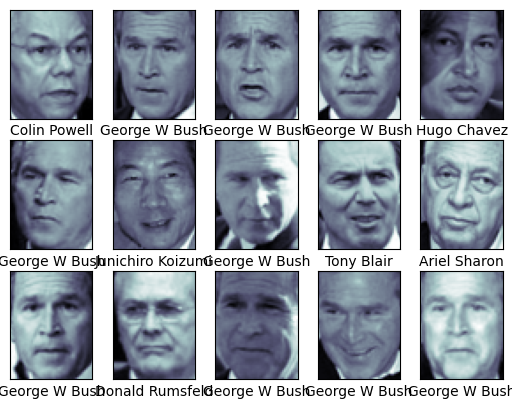

In [2]:
# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.show()

## Langkah 2 - Pra Pengolahan Data

In [3]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

## Langkah 3 - Split Data

In [4]:
# pemisahan data training dan data testing
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target,
                                                random_state=42)
print('Data latih:', Xtrain.shape)
print('Data uji  :', Xtest.shape)

Data latih: (1011, 2914)
Data uji  : (337, 2914)


## Langkah 4 - Pembuatan Model + Tuning

In [5]:
import time
from sklearn.model_selection import GridSearchCV

param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

t0 = time.time()
grid.fit(Xtrain, ytrain)
print(f'Wall time: {time.time() - t0:.1f} detik')

print(grid.best_params_)
print(grid.best_score_)

Wall time: 17.9 detik
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


Pelatihan model menggabungkan dua teknik penting melalui `Pipeline`:
1. **Reduksi Dimensi dengan PCA (*Eigenfaces*):** Mengurangi dimensi fitur dari 2.914 piksel menjadi 150 komponen utama paling representatif dengan parameter `whiten=True` untuk memastikan seluruh komponen memiliki skala variansi seragam dan tidak berkorelasi. Reduksi ini memangkas lebih dari 94% dimensi data sekaligus mempercepat waktu pelatihan secara drastis.
2. **Hyperparameter Tuning via GridSearchCV:** Menguji 16 kombinasi parameter penalti margin `C` (1, 5, 10, 50) dan lebar kernel RBF `gamma` (0.0001, 0.0005, 0.001, 0.005).

Pencarian sistematis menghasilkan kombinasi terbaik pada `C = 5` dan `gamma = 0.001` dengan rata-rata skor akurasi validasi silang mencapai **82,88%**. Nilai `C=5` memberikan fleksibilitas margin yang pas tanpa membiarkan model terlalu kaku (*overfitting*), sementara `gamma=0.001` menciptakan batas kelengkungan RBF yang cukup halus pada ruang 150 dimensi PCA.

In [6]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

## Langkah 5 - Cek Hasil Prediksi

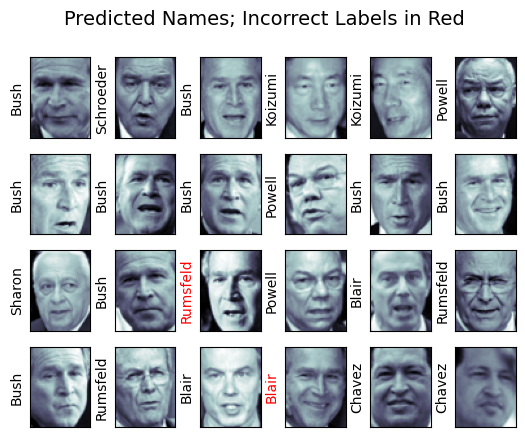

In [7]:
# hasil label pada data testing
fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)
plt.show()

In [8]:
salah = (yfit != ytest)
print('Dari 24 wajah yang ditampilkan, salah prediksi:', salah[:24].sum())
print('Dari seluruh data uji, salah prediksi         :', salah.sum(), 'dari', len(ytest))

Dari 24 wajah yang ditampilkan, salah prediksi: 2
Dari seluruh data uji, salah prediksi         : 51 dari 337


## Langkah 6 - Cek Performansi

In [9]:
from sklearn.metrics import classification_report

print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Pada data uji independen sebanyak 337 citra wajah, model SVM terbaik mampu mencapai **akurasi keseluruhan sebesar 85%**:
- **Junichiro Koizumi** mencatatkan *recall* sempurna **1,00** (12 dari 12 foto ditebak tepat) dengan F1-score **0,92**.
- **Tony Blair** meraih *recall* **0,98** dan F1-score **0,89** (41 dari 42 foto tepat).
- **George W Bush** memiliki *precision* tertinggi mencapai **0,97**, membuktikan bahwa citra yang diprediksi sebagai Bush hampir selalu benar.
- Penggunaan parameter `class_weight='balanced'` pada SVC terbukti krusial untuk mencegah model mendominasi tebakan ke arah kelas George W Bush yang memiliki jumlah sampel terbanyak.

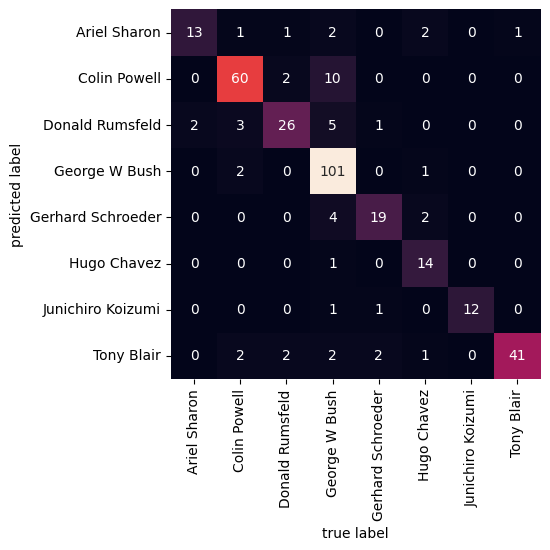

In [10]:
# bentuk confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.show()

Heatmap *Confusion Matrix* di atas memperlihatkan dominasi nilai yang sangat kuat di sepanjang diagonal utama (klasifikasi tepat). Pola kesalahan yang terjadi umumnya berupa kesalahan klasifikasi minor ke arah George W Bush (karena jumlah sampel referensi latih Bush yang dominan), seperti beberapa citra Colin Powell (8 foto) dan Gerhard Schroeder (3 foto) yang salah diprediksi. Secara keseluruhan, kombinasi PCA 150 komponen dan SVM RBF terbukti efektif dan tangguh untuk pengenalan wajah multi-kelas pada data citra riil.